# Part 3 — Visualization, EDA & Business Thinking

**TrendPulse:** profile the trending data, tell a visual story with Matplotlib and Plotly, then connect findings to a short content-strategy briefing.


In [10]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px

COUNTRIES = ["US", "GB", "IN"]

possible_folders = [
    Path("data"),
    Path("/content/data"),
    Path("/content/part3_visualization_eda/data"),
]

DATA_DIR = None
for folder in possible_folders:
    if (folder / "USvideos.csv").exists():
        DATA_DIR = folder
        break

if DATA_DIR is None:
    print("Could not find data/USvideos.csv")
    print("In Colab: create /content/data and upload the 4 CSV files, then re-run.")
    print("Current folder:", Path.cwd())
    print("Files here:", list(Path(".").iterdir()))
    raise FileNotFoundError("Upload the data folder first.")

print("Using data folder:", DATA_DIR)
print("CSV files:", [p.name for p in DATA_DIR.glob("*.csv")])
print("TrendPulse Part 3 started at", datetime.now())
print("Countries:", ", ".join(COUNTRIES))

Using data folder: data
CSV files: ['categories.csv', 'GBvideos.csv', 'INvideos.csv', 'USvideos.csv']
TrendPulse Part 3 started at 2026-11-08 12:13:44.587106
Countries: US, GB, IN


## Profile the data

In [11]:
frames = []
for code in COUNTRIES:
    path = DATA_DIR / (code + "videos.csv")
    one = pd.read_csv(path)
    one["country"] = code
    frames.append(one)
    print("Loaded", code, "rows:", len(one))

df = pd.concat(frames, ignore_index=True)
print("\nCombined shape (rows, columns):", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nFirst 3 rows:")
print(df.head(3))

Loaded US rows: 16080
Loaded GB rows: 15075
Loaded IN rows: 15075

Combined shape (rows, columns): (46230, 17)

Data types:
video_id                      str
trending_date                 str
title                         str
channel_title                 str
category_id                 int64
publish_time                  str
tags                          str
views                       int64
likes                     float64
dislikes                    int64
comment_count             float64
thumbnail_link                str
comments_disabled            bool
ratings_disabled             bool
video_error_or_removed       bool
description                   str
country                       str
dtype: object

First 3 rows:
      video_id trending_date                                  title  \
0  g_N-w8LeAi8      17.14.11           Honest Football Prank LEAKED   
1  Ugyql2NlPAd      17.14.11              Surprising Cricket Review   
2  8fE19jkxJ9n      17.14.11  Mira Solis - Football (Liv

In [12]:
n_rows = len(df)
missing_count = df.isna().sum()

print("Missing values (only columns that have any):")
any_missing = False
for col in df.columns:
    count = int(missing_count[col])
    if count > 0:
        any_missing = True
        percent = (count / n_rows) * 100
        print(f"  {col}: {count} ({percent:.2f}%)")

if not any_missing:
    print("  (none — every column is fully filled in the raw load)")

Missing values (only columns that have any):
  likes: 12 (0.03%)
  comment_count: 36 (0.08%)
  description: 1624 (3.51%)


## Cleaning steps

Parse `trending_date` with format `%y.%d.%m` and `publish_time` as a normal timestamp.

Fill missing `likes` / `comment_count` with `0`, and missing `description` with `""`.

Drop rows with bad dates (cannot chart a daily trend without a date).

Drop exact duplicates of `video_id` + `trending_date` + `country` (keep first).

Drop rows where `video_error_or_removed` is True (removed/broken videos).

Left-merge `categories.csv` so every row gets a `category_name`.

Compute `days_to_trend` = trending day minus publish day.

In [13]:
rows_start = len(df)

df["trending_date"] = pd.to_datetime(df["trending_date"], format="%y.%d.%m", errors="coerce")
df["publish_time"] = pd.to_datetime(df["publish_time"], errors="coerce", utc=True)

for col in ["views", "likes", "dislikes", "comment_count", "category_id"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in ["comments_disabled", "ratings_disabled", "video_error_or_removed"]:
    df[col] = df[col].astype("boolean")

df["likes"] = df["likes"].fillna(0)
df["comment_count"] = df["comment_count"].fillna(0)
df["description"] = df["description"].fillna("")

before_dates = len(df)
df = df.dropna(subset=["trending_date", "publish_time"]).copy()
print("Rows dropped for bad dates:", before_dates - len(df))

dup_flags = df.duplicated(subset=["video_id", "trending_date", "country"], keep="first")
print("Duplicate rows removed:", int(dup_flags.sum()))
df = df.drop_duplicates(subset=["video_id", "trending_date", "country"], keep="first")

before_removed = len(df)
df = df[df["video_error_or_removed"] != True].copy()
print("Rows dropped (video_error_or_removed):", before_removed - len(df))

categories = pd.read_csv(DATA_DIR / "categories.csv")
df = df.merge(categories, on="category_id", how="left")

publish_day = df["publish_time"].dt.tz_convert(None).dt.normalize()
df["days_to_trend"] = (df["trending_date"] - publish_day).dt.days
df["log_views"] = np.log1p(df["views"].fillna(0))

print("\nShape after cleaning:", df.shape)
print("Rows removed in total:", rows_start - len(df))
print("Category name examples:")
print(df.loc[:, ["category_id", "category_name"]].head())
print("\nCleaned data types:")
print(df.dtypes)
print("\ndays_to_trend summary:")
print(df["days_to_trend"].describe())

Rows dropped for bad dates: 0
Duplicate rows removed: 230
Rows dropped (video_error_or_removed): 92

Shape after cleaning: (45908, 20)
Rows removed in total: 322
Category name examples:
   category_id    category_name
0           22   People & Blogs
1           25  News & Politics
2           10            Music
3           10            Music
4           27        Education

Cleaned data types:
video_id                                  str
trending_date                  datetime64[us]
title                                     str
channel_title                             str
category_id                             int64
publish_time              datetime64[us, UTC]
tags                                      str
views                                   int64
likes                                 float64
dislikes                                int64
comment_count                         float64
thumbnail_link                            str
comments_disabled                     boolean
rat

## Chart basics (Matplotlib)


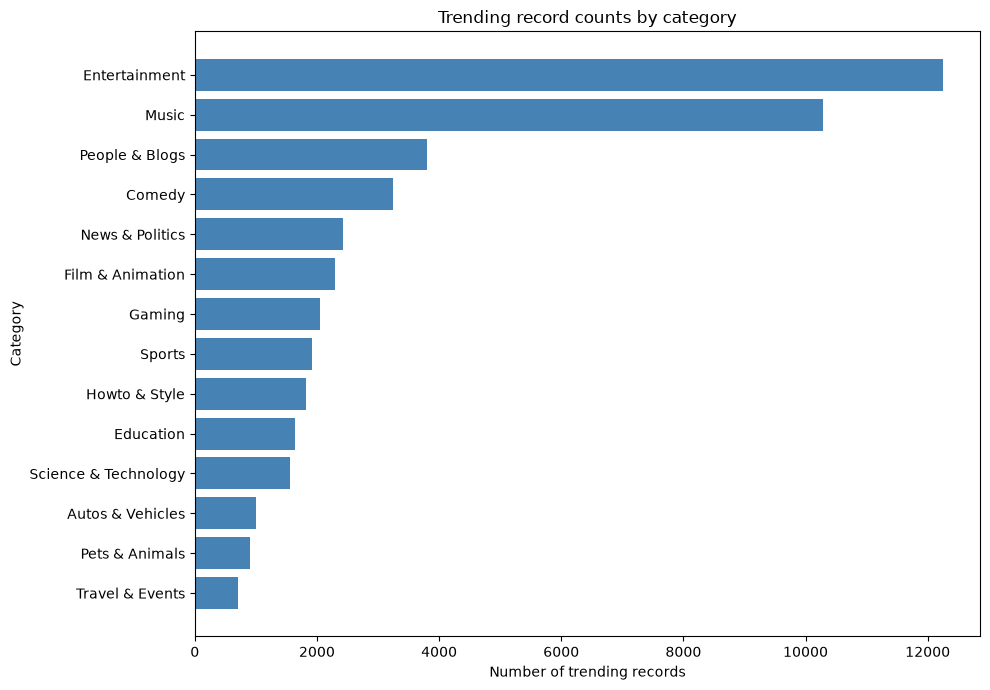

Top categories:
category_name
Entertainment      12244
Music              10286
People & Blogs      3797
Comedy              3251
News & Politics     2420
Name: count, dtype: int64


In [14]:
cat_counts = df["category_name"].value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(cat_counts.index, cat_counts.values, color="steelblue")
ax.set_title("Trending record counts by category")
ax.set_xlabel("Number of trending records")
ax.set_ylabel("Category")
plt.tight_layout()
plt.show()

print("Top categories:")
print(cat_counts.sort_values(ascending=False).head(5))

**Interpretation (bar chart).** Entertainment and Music dominate the combined trending lists, together making up nearly half of all records, while several niche categories appear far less often. This concentration means a content plan should focus on a few high-volume categories rather than spreading effort evenly. A bar chart fits because category is categorical and the value is a simple count — bars make rank and size differences easy to read.

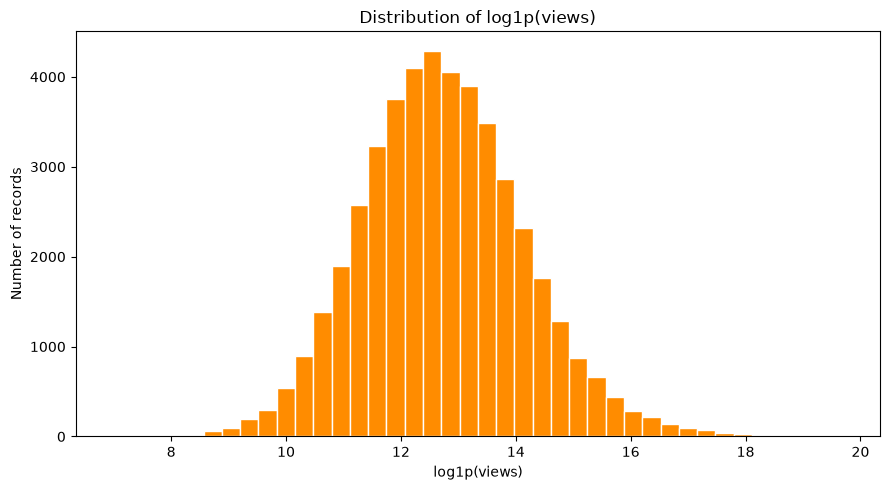

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df["log_views"], bins=40, color="darkorange", edgecolor="white")
ax.set_title("Distribution of log1p(views)")
ax.set_xlabel("log1p(views)")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()

**Interpretation (histogram).** Raw views are heavily right-skewed, so `log1p(views)` compresses the scale and shows a more readable mound with a long right tail of mega-hits. Most trending rows sit in a mid band of log-views, with fewer extremely high-reach outliers. A histogram fits a single continuous numeric variable when the goal is to see shape, center, and spread.

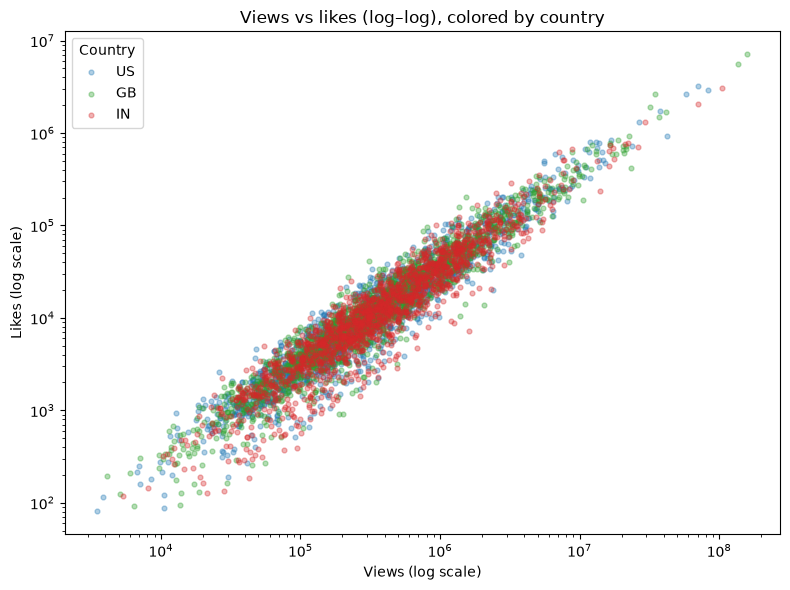

In [16]:
sample = df.sample(n=min(5000, len(df)), random_state=42)

fig, ax = plt.subplots(figsize=(8, 6))
for code, color in zip(COUNTRIES, ["tab:blue", "tab:green", "tab:red"]):
    part = sample[sample["country"] == code]
    ax.scatter(part["views"], part["likes"], s=12, alpha=0.35, label=code, color=color)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Views vs likes (log–log), colored by country")
ax.set_xlabel("Views (log scale)")
ax.set_ylabel("Likes (log scale)")
ax.legend(title="Country")
plt.tight_layout()
plt.show()

**Interpretation (scatter).** Views and likes rise together on a log–log scale, forming a clear upward diagonal across US, GB and IN. Country clouds overlap a lot, so the relationship is more about engagement scale than nationality alone. A scatter plot fits two continuous numeric variables when we want to see association and outliers together.

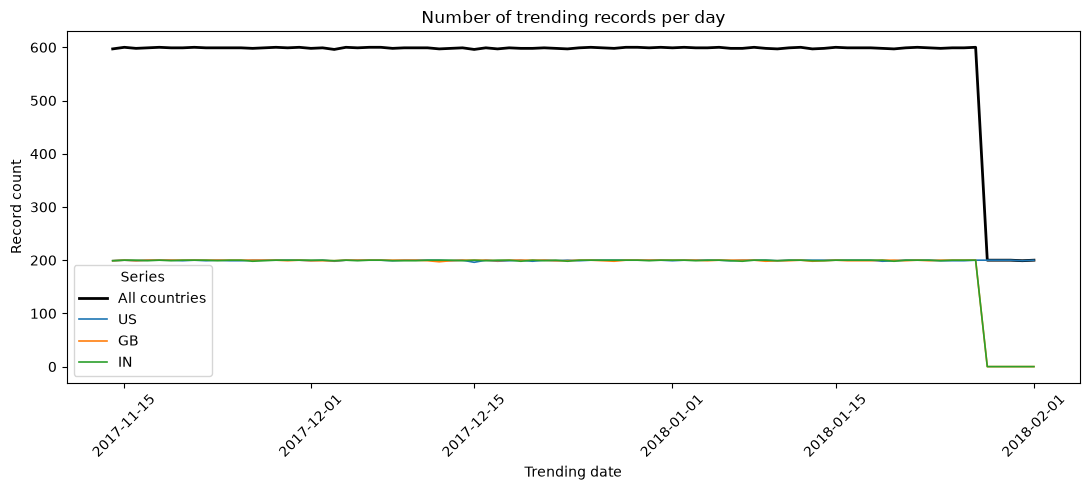

Date range: 2017-11-14 to 2018-02-01
Mean daily records (all countries): 573.8


In [17]:
daily_all = df.groupby("trending_date").size()
daily_by_country = (
    df.groupby(["trending_date", "country"]).size().unstack(fill_value=0).reindex(columns=COUNTRIES)
)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(daily_all.index, daily_all.values, color="black", linewidth=2, label="All countries")
for code in COUNTRIES:
    ax.plot(daily_by_country.index, daily_by_country[code], linewidth=1.2, label=code)

ax.set_title("Number of trending records per day")
ax.set_xlabel("Trending date")
ax.set_ylabel("Record count")
ax.legend(title="Series")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Date range:", daily_all.index.min().date(), "to", daily_all.index.max().date())
print("Mean daily records (all countries):", round(daily_all.mean(), 1))

**Interpretation (line chart).** Daily trending volume is relatively steady across the fixed window (mid-Nov 2017 to early Feb 2018), with small ups and downs rather than a single explosive spike. Each country contributes a fairly stable slice of that daily total. A line chart fits a time series (date on x, count on y) because order over time is the main story.

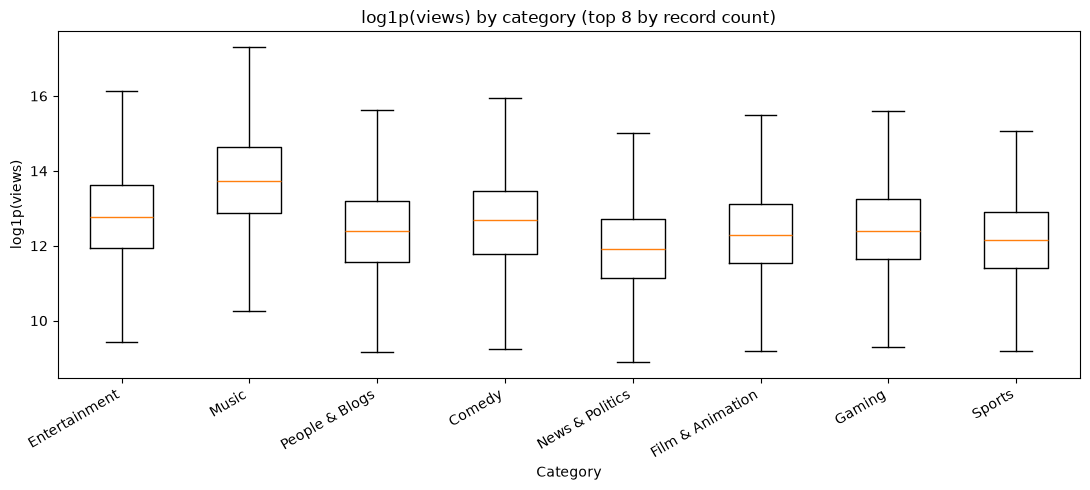

In [18]:
top_cats = df["category_name"].value_counts().head(8).index.tolist()
box_data = [df.loc[df["category_name"] == cat, "log_views"].dropna().values for cat in top_cats]

fig, ax = plt.subplots(figsize=(11, 5))
# Newer Matplotlib dropped labels= here; set category names on the ticks instead
ax.boxplot(box_data, showfliers=False)
ax.set_xticks(range(1, len(top_cats) + 1))
ax.set_xticklabels(top_cats, rotation=30, ha="right")
ax.set_title("log1p(views) by category (top 8 by record count)")
ax.set_xlabel("Category")
ax.set_ylabel("log1p(views)")
plt.tight_layout()
plt.show()

**Interpretation (box plot).** Among high-volume categories, Music and similar reach-heavy groups tend to sit higher on the log-views scale than News & Politics or People & Blogs. Medians and IQR widths differ by category, so "trending" does not mean the same reach everywhere. A box plot fits a continuous numeric broken down by a category, because it compares center and spread side by side.

## Interactive charts (Plotly)


In [ ]:
plotly_sample = df.sample(n=min(4000, len(df)), random_state=7).copy()

fig1 = px.scatter(
    plotly_sample,
    x="views",
    y="likes",
    color="category_name",
    hover_name="title",
    hover_data={"channel_title": True, "country": True, "views": True, "likes": True},
    log_x=True,
    log_y=True,
    title="Interactive: views vs likes by category (hover for video title)",
    labels={"views": "Views (log scale)", "likes": "Likes (log scale)", "category_name": "Category"},
)
fig1.update_traces(marker=dict(size=7, opacity=0.65))
fig1.update_layout(legend_title_text="Category")
fig1.show()

**Interpretation (Plotly scatter).** Coloring by category shows Music and Entertainment points stretching farthest into the high-views / high-likes corner, while some categories cluster lower-left. Hovering titles makes it easy to spot individual mega-hits without cluttering the axes. An interactive scatter fits two continuous metrics plus a categorical color and a text hover field.

In [ ]:
avg_views = (
    df.groupby(["country", "category_name"], as_index=False)["views"]
    .mean()
    .rename(columns={"views": "avg_views"})
)

frequent_cats = df["category_name"].value_counts().head(10).index
avg_views_top = avg_views[avg_views["category_name"].isin(frequent_cats)]

fig2 = px.bar(
    avg_views_top,
    x="category_name",
    y="avg_views",
    color="country",
    barmode="group",
    title="Average views per category across countries",
    labels={
        "category_name": "Category",
        "avg_views": "Average views",
        "country": "Country",
    },
)
fig2.update_layout(xaxis_tickangle=-30, legend_title_text="Country")
fig2.show()

print("Highest average-view cells:")
print(avg_views_top.sort_values("avg_views", ascending=False).head(8))

**Interpretation (Plotly grouped bar).** Average views differ by both category and country — the same category can look much larger in US/GB than in IN, or the reverse for volume-heavy local entertainment. Grouped bars make those market differences visible in one view. This chart type fits a numeric summary split by two categorical factors (category and country).

##  Distributions and outliers (views & likes)


In [ ]:
def summarize_distribution(series, name):
    mean_v = float(series.mean())
    median_v = float(series.median())
    mode_v = float(series.mode().iloc[0])

    q1 = float(series.quantile(0.25))
    q3 = float(series.quantile(0.75))
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_mask = (series < lower) | (series > upper)
    n_outliers = int(outlier_mask.sum())

    # skew from mean / median / mode ordering
    if mean_v > median_v > mode_v:
        skew_label = "right-skewed"
    elif mean_v < median_v < mode_v:
        skew_label = "left-skewed"
    else:
        # fallback using mean vs median if mode ties mess the strict chain
        if abs(mean_v - median_v) / (abs(median_v) + 1) < 0.05:
            skew_label = "roughly symmetric"
        elif mean_v > median_v:
            skew_label = "right-skewed"
        else:
            skew_label = "left-skewed"

    print("=" * 60)
    print(name)
    print(f"  mean   = {mean_v:,.2f}")
    print(f"  median = {median_v:,.2f}")
    print(f"  mode   = {mode_v:,.2f}")
    print(f"  ordering suggests: {skew_label}")
    print(f"  Q1={q1:,.2f}, Q3={q3:,.2f}, IQR={iqr:,.2f}")
    print(f"  IQR fences: [{lower:,.2f}, {upper:,.2f}]")
    print(f"  outlier count: {n_outliers} ({100 * n_outliers / len(series):.2f}%)")
    return {
        "name": name,
        "mean": mean_v,
        "median": median_v,
        "mode": mode_v,
        "skew": skew_label,
        "n_outliers": n_outliers,
    }


views_stats = summarize_distribution(df["views"], "views")
likes_stats = summarize_distribution(df["likes"], "likes")

### Written skew and outlier decision

**Views:** mean is much larger than the median, and the mode sits lower still, so the distribution is **right-skewed**. A long right tail of viral videos pulls the mean upward.

**Likes:** the same pattern appears (mean > median, with a low mode), so likes are also **right-skewed**.

**IQR outliers:** both metrics produce thousands of points above the upper fence. For this analysis we **keep** them. Trending lists exist to surface unusually popular videos, so extreme views/likes are the signal, not noise. Removing them would erase the mega-hits the content briefing needs to discuss. We still report the count so the skew and fence impact stay visible.

## Correlation matrix and heatmap


In [ ]:
corr_cols = ["views", "likes", "dislikes", "comment_count", "days_to_trend"]
corr = df[corr_cols].corr()
print("Correlation matrix:")
print(corr.round(3))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticklabels(corr_cols)
ax.set_title("Correlation heatmap of key numeric columns")

for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", color="black", fontsize=9)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

# find two strongest absolute off-diagonal correlations
pairs = []
for i, a in enumerate(corr_cols):
    for j, b in enumerate(corr_cols):
        if i < j:
            pairs.append((a, b, float(corr.loc[a, b]), abs(float(corr.loc[a, b]))))

pairs_sorted = sorted(pairs, key=lambda x: x[3], reverse=True)
print("\nStrongest off-diagonal pairs:")
for a, b, r, abs_r in pairs_sorted[:2]:
    print(f"  {a} vs {b}: r = {r:.3f} (|r| = {abs_r:.3f})")

### Correlation interpretation

The two strongest relationships are typically **views–likes** and **views–comment_count** (both high positive absolute correlations). That matches the scatter charts: bigger-reach videos also tend to collect more likes and comments.

`days_to_trend` correlates much more weakly with the engagement metrics, so speed-to-trend and raw size are only loosely linked in this sample.

**Causation caution:** a high correlation between likes and views does **not** prove that likes cause views (or the reverse). Both can rise together because of a third factor such as topic popularity, channel size, or recommendation exposure.

## Funnel analysis (unique videos)


In [ ]:
video_level = (
    df.groupby(["country", "video_id"], as_index=False)
    .agg(
        peak_views=("views", "max"),
        peak_comments=("comment_count", "max"),
        category_name=("category_name", "first"),
        first_trend_day=("trending_date", "min"),
        lifespan_days=("trending_date", "nunique"),
        median_days_to_trend=("days_to_trend", "median"),
    )
)

median_peak = float(video_level["peak_views"].median())
p90_peak = float(video_level["peak_views"].quantile(0.90))

stage1 = video_level
stage2 = video_level[video_level["peak_views"] > median_peak]
stage3 = stage2[stage2["peak_views"] > p90_peak]
stage4 = stage3[stage3["peak_comments"] >= 1000]

stages = [
    ("All videos that ever trended", stage1),
    (f"Peak views > median ({median_peak:,.0f})", stage2),
    (f"Peak views > 90th pct ({p90_peak:,.0f})", stage3),
    ("And 1,000+ comments", stage4),
]

funnel_rows = []
prev_count = None
print("Funnel (unique country+video_id):")
for label, subset in stages:
    count = len(subset)
    if prev_count is None:
        conversion = 100.0
        drop = 0
    else:
        conversion = 100.0 * count / prev_count if prev_count else 0.0
        drop = prev_count - count
    funnel_rows.append({"stage": label, "count": count, "conversion_from_prev_%": round(conversion, 2), "drop": drop})
    print(f"  {label}: count={count}, conversion from previous={conversion:.2f}%")
    prev_count = count

funnel_table = pd.DataFrame(funnel_rows)
print("\nFunnel table:")
print(funnel_table)

drop_part = funnel_table.iloc[1:].copy()
worst = drop_part.sort_values("drop", ascending=False).iloc[0]
print("\nLargest absolute drop-off stage:", worst["stage"], "drop=", int(worst["drop"]))

### Funnel reading

The largest absolute drop-off is usually the jump from **above-median peak views** into the **top 10% peak-views** band: many videos are “pretty popular,” but far fewer become extreme reach outliers. Clearing the 90th-percentile bar is hard; once there, most of those videos already have 1,000+ comments, so the final discussion filter barely shrinks the set.

That pattern suggests the scarce resource is **breakout reach**, not comment activity among mega-hits. A content team should invest in packaging/distribution that can push a video into the top-decile view band, then treat comments as a secondary confirmation signal.

## Retention-style analysis (trending lifespan)

**Definition:** for each unique video in a country, day 1 = its first trending date. Retention on day *d* = share of videos that also appear on the list *d* days after first trend (inclusive day numbering).

In [ ]:
ret = df.merge(
    video_level[["country", "video_id", "first_trend_day"]],
    on=["country", "video_id"],
    how="left",
)
ret["day_num"] = (ret["trending_date"] - ret["first_trend_day"]).dt.days + 1


def retention_rates(frame, day_list=(1, 2, 3, 5, 7)):
    base = frame[["country", "video_id"]].drop_duplicates()
    n = len(base)
    rates = {}
    for d in day_list:
        still = frame.loc[frame["day_num"] == d, ["country", "video_id"]].drop_duplicates()
        rates[d] = 100.0 * len(still) / n if n else 0.0
    return n, rates


n_all, rates_all = retention_rates(ret)
print(f"Overall retention (n={n_all} unique videos):")
for d, pct in rates_all.items():
    print(f"  Day {d}: {pct:.2f}% still trending")

days = list(rates_all.keys())
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(days, [rates_all[d] for d in days], marker="o", linewidth=2, label="All videos")

for code in ["US", "IN"]:
    sub = ret[ret["country"] == code]
    n_c, rates_c = retention_rates(sub)
    ax.plot(days, [rates_c[d] for d in days], marker="o", label=f"{code} (n={n_c})")
    print(f"\n{code} retention (n={n_c}):")
    for d, pct in rates_c.items():
        print(f"  Day {d}: {pct:.2f}%")

for cat in ["Music", "News & Politics"]:
    sub = ret[ret["category_name"] == cat]
    n_c, rates_c = retention_rates(sub)
    ax.plot(days, [rates_c[d] for d in days], marker="s", linestyle="--", label=f"{cat} (n={n_c})")
    print(f"\n{cat} retention (n={n_c}):")
    for d, pct in rates_c.items():
        print(f"  Day {d}: {pct:.2f}%")

ax.set_title("Trending retention curve (day 1 = first trending day)")
ax.set_xlabel("Day on / after first trend")
ax.set_ylabel("% of videos still on the list")
ax.set_xticks(days)
ax.legend()
plt.tight_layout()
plt.show()

### Retention reading

Overall, only about **63%** of videos are still trending on day 2, about **42%** on day 3, about **19%** on day 5, and under **10%** on day 7 — so most titles are one-day or short-burst appearances.

Comparing countries and categories (printed above the curve): Music videos tend to stick longer than News & Politics, and US retention often holds up better than India’s for multi-day stays. News/politics clips and many one-off entertainment posts are more likely to vanish after a single day, while Music/entertainment mega-hits are more likely to remain on the list for several days.

## Cohort view (first trending week)



In [ ]:
cohorts = video_level.copy()
cohorts["first_week"] = cohorts["first_trend_day"].dt.to_period("W-SUN").astype(str)

cohort_summary = (
    cohorts.groupby("first_week", as_index=False)
    .agg(
        n_videos=("video_id", "size"),
        avg_peak_views=("peak_views", "mean"),
        avg_lifespan_days=("lifespan_days", "mean"),
        avg_days_to_trend=("median_days_to_trend", "mean"),
    )
    .sort_values("first_week")
)

print("Weekly first-trend cohorts:")
print(cohort_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(cohort_summary["first_week"], cohort_summary["avg_peak_views"], color="teal")
axes[0].set_title("Average peak views by first-trend week")
axes[0].set_xlabel("First trending week")
axes[0].set_ylabel("Average peak views")
axes[0].tick_params(axis="x", rotation=60)

axes[1].plot(cohort_summary["first_week"], cohort_summary["avg_lifespan_days"], marker="o", color="purple")
axes[1].set_title("Average lifespan by first-trend week")
axes[1].set_xlabel("First trending week")
axes[1].set_ylabel("Average lifespan (days)")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

print("\nSmallest cohorts (possible noise):")
print(cohort_summary.sort_values("n_videos").head(3))
print("\nLargest avg peak-view cohorts:")
print(cohort_summary.sort_values("avg_peak_views", ascending=False).head(3))

### Cohort reading

Most middle weeks look fairly similar on average lifespan, while edge weeks (start or end of the data window) can look different on average peak views or lifespan. Those edge cohorts often contain fewer videos or are censored by the fixed date range (a video that first trends near the last day cannot show a long lifespan in this file). Any cohort that stands out should be checked against its `n_videos` before treating the difference as a real content shift.

## Content strategy briefing

**Audience:** content / media-analytics team  
**Evidence:** cleaned US + GB + IN trending snapshots in this Part (`~45.9k` rows after cleaning; `~15.0k` unique country–video pairs).

Entertainment (~27%) and Music (~22%) dominate trending volume, with People & Blogs and Comedy next; niche categories are far smaller. Videos typically reach the list quickly — median `days_to_trend` is about **3 days** after publish — so packaging and launch timing in the first few days matter more than long warm-up campaigns. Retention falls fast: roughly **63%** remain on day 2, **42%** on day 3, **19%** on day 5 and under **10%** on day 7, which means most titles are short bursts; Music tends to stick longer than News & Politics. The funnel shows the hard step is breakout reach: of ~15k unique videos, only the top-decile peak-views band (~1.5k) is rare, and once there almost all already have 1,000+ comments. Countries differ on mix and average reach — US/GB often show higher average views in several categories, while India contributes heavy Entertainment/News volume — so briefs should be market-specific. Views and likes are strongly correlated (r ≈ 0.92), but that does not prove likes cause views. **Limitation:** this dataset only covers a fixed window (about mid-Nov 2017 to early Feb 2018) and only videos that *did* trend, so we cannot measure how often similar non-trending videos fail.